# AP 155 Lab Exercise
---
## Exercise 12: More Integration

_Instructions_: 
- **Problem 1**: Figure: Diffraction Pattern, discussion: Explain the figure
- **Problem 2**: Figure: Gamma Function, discussion: *What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?*
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Hernando, Claire Marie M. 
- _Student No._: 2024-12904
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Diffraction limit of a telescope

![Screenshot 2026-11-09 at 5.08.50 PM.png](DiffLimitTelescopeNeumann5-4.png)


Hint 1: You may find it useful to know that $\lim_{x→0} J_1(x)/x = 1/2$ 

Hint 2: The central
spot in the diffraction pattern is so bright that it may be difficult to see the rings around
it on the computer screen. If you run into this problem a simple way to deal with it is to
use one of the other color schemes for density plots described in Section 3.3. The “hot”
scheme works well. For a more sophisticated solution to the problem, the imshow function has an additional argument vmax that allows you to set the value that corresponds
to the brightest point in the plot. For instance, if you say `imshow(x,vmax=0.1)`, then elements in x with value 0.1, or any greater value, will produce the brightest (most positive) color on the screen. By lowering the `vmax` value, you can reduce the total range of
values between the minimum and maximum brightness, and hence increase the sensitivity of the plot, making subtle details visible. (There is also a `vmin` argument that can
be used to set the value that corresponds to the dimmest (most negative) color.) For this
exercise a value of `vmax=0.01` appears to work well.

### Part A

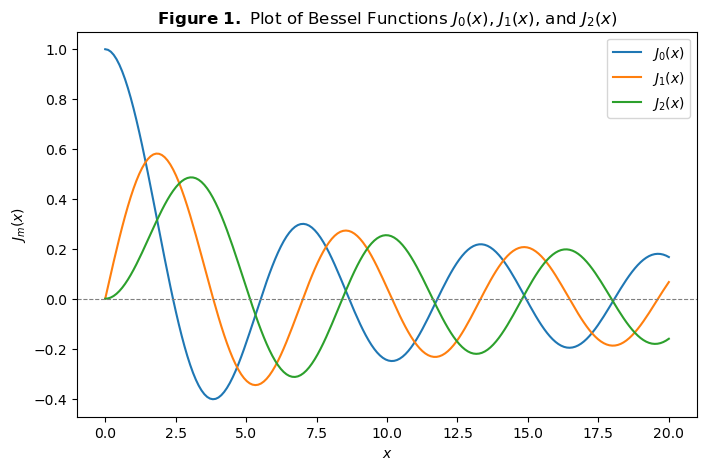

In [5]:
def J(m, x):
    N = 1000
    a = 0.0
    b = np.pi 

    # Applying 1/3 Simpson's Rule 
    if N % 2 == 0:
        N += 1
    
    h = (b - a) / (N - 1) 

    # Setting up theta points
    theta = a + np.arange(N) * h

    # Setting up the function
    f = np.cos(m * theta - x * np.sin(theta))

    # Setting up coefficient
    cs = 2 * np.ones(N)
    cs[0] = 1
    cs[-1] = 1
    cs[1::2] = 4

    # Solving integral 
    integral = (1/3) * h * np.sum(cs * f) 
    return (1/np.pi) * integral 

# Plotting values 
xvals = np.linspace(0, 20, 200)
m_vals = [0, 1, 2]

fig, ax = plt.subplots(figsize=(8,5))
for m in m_vals:
    yvals = [J(m,x) for x in xvals]
    ax.plot(xvals, yvals, label=f"$J_{m}(x)$")

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title(r"$\bf{Figure\ 1.}$ Plot of Bessel Functions $J_0(x)$, $J_1(x)$, and $J_2(x)$")
plt.xlabel("$x$")
plt.ylabel("$J_m(x)$")
plt.legend()
plt.grid(False)
plt.show()   

### Part B

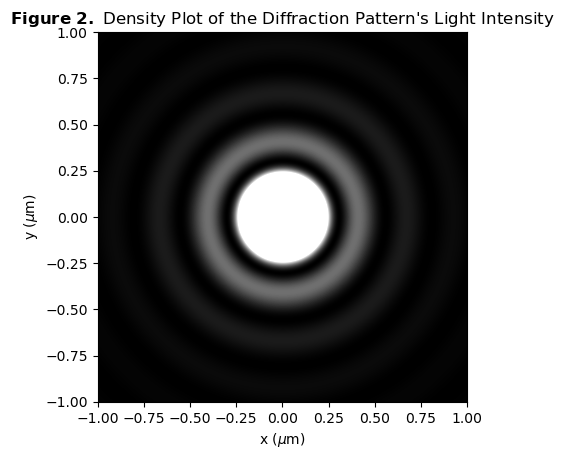

In [22]:
# Defining variables
lam = 500/1000 # Convert from nm to um
k = 2 * np.pi / lam

# Setting up coordinate grid 
r = 1.0 # this is the radius
points = 400 
x = np.linspace(-r, r, points) # 1D array representing the straight line of coordinates
y = np.linspace(-r, r, points) 
X, Y = np.meshgrid(x, y) # Uses 1D array to create a 2D array like a grid 
R = np.sqrt(X**2 + Y**2) # Calculating radial distance in 2D grid 

# Evaluating the Bessel function one point at a time
kr = k * R
I = np.zeros((points, points)) # empty 2D array to store the intensity

# Considering limits of J_1(x)/x as x approaches 0 --> yields to 1/2
for i in range(points):
    for j in range(points):
        if kr[i, j] == 0:
            frac = 0.5 
        else:
            frac = J(1, kr[i, j]) / kr[i, j]
        I[i, j] = frac**2

# Plotting the density plot 
plt.figure()
plt.imshow(I, vmax=0.01, extent=[-r, r, -r, r])
plt.xlabel(r"x ($\mu$m)")
plt.ylabel(r"y ($\mu$m)")
plt.title(r"$\bf{{Figure\ 2.}}$ Density Plot of the Diffraction Pattern's Light Intensity")
plt.gray()
plt.show()

Report discussion: Explain the figure

### Problem 2: Integration via Monte Carlo with Importance sampling

Evaluate the gamma function for $z\in [1,5]. $ $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} \, dt $$ Plot the function using your integration method vs `scipy.special.gamma` (two curves)

Use monte carlo method with importance sampling, by recasting the integral into the form 

$$ \int f(x)dx = \int g(x)p(x)dx, \ \  g(x) = \frac{f(x)}{p(x)}$$



Report discussion: What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma

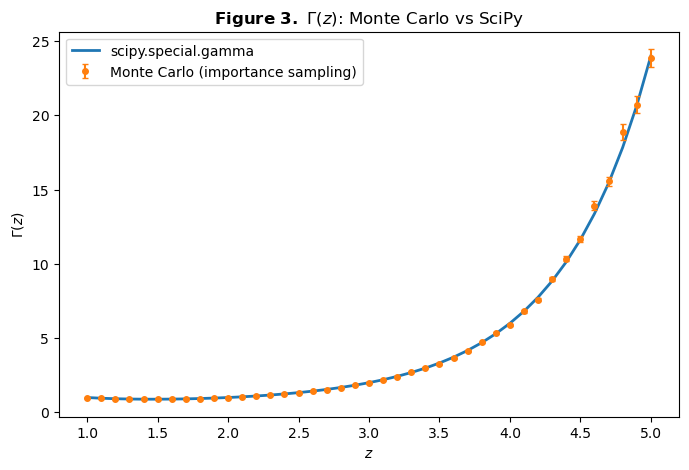

s = 1.0: estimate = 22.225 +/- 0.469, exact = 24.000
s = 5.0: estimate = 24.076 +/- 0.066, exact = 24.000


In [25]:
# Monte Carlo with importance sampling for Gamma(z)
def gamma_mc(z, N=100000, s=1.0):
    # Sampling t from p(t) = exp(-t/s)/s
    t = np.random.exponential(scale=s, size=N)

    # Setting up f(t), p(t), and g(t) = f(t)/p(t)
    f = t**(z - 1) * np.exp(-t)
    p = np.exp(-t / s) / s
    g = f / p

    # Estimate = mean of g, error = standard error of the mean
    estimate = np.mean(g)
    error = np.std(g) / np.sqrt(N)
    return estimate, error

# Evaluating over z in [1, 5]
zvals = np.linspace(1, 5, 41)
mc_vals = []
mc_errs = []
for z in zvals:
    est, err = gamma_mc(z, N=100000, s=1.0)
    mc_vals.append(est)
    mc_errs.append(err)

mc_vals = np.array(mc_vals)
mc_errs = np.array(mc_errs)

# Plotting both curves
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(zvals, gamma(zvals), label="scipy.special.gamma", linewidth=2)
ax.errorbar(zvals, mc_vals, yerr=mc_errs, fmt="o", markersize=4,
            capsize=2, label="Monte Carlo (importance sampling)")
plt.title(r"$\bf{Figure\ 3.}$ $\Gamma(z)$: Monte Carlo vs SciPy")
plt.xlabel("$z$")
plt.ylabel(r"$\Gamma(z)$")
plt.legend()
plt.grid(False)
plt.show()

# Compare errors for different choices of p(t) at z = 5
for s in [1.0, 5.0]:
    est, err = gamma_mc(5, N=100000, s=s)
    print(f"s = {s}: estimate = {est:.3f} +/- {err:.3f}, exact = {gamma(5):.3f}")